# 03 Evaluate: how good are the forecasts in the backtest?

**Purpose:** Compute the backtest errors of all candidate models, per horizon, in units a planner understands; compare the models at the main horizon ($h = 2$), also without the crisis periods and year by year; check whether the route indicator helps; choose the final model (**Part A**, sections 1 to 8, written before the test). **Part B** (sections 9 to 19, added after the test) evaluates the second model family, the regressions with **all indicators**, shows which data lower the error the most, and adds a third simple rule and a one-year horizon, with the same rules.
**Input:** `../data/processed/backtest_forecasts.csv` (from `02_estimate.ipynb`), `../data/processed/backtest_forecasts_regression.csv` (from `02b_estimate_regression.ipynb`) and `../data/processed/backtest_forecasts_indicator.csv` (from `02c_estimate_indicator.ipynb`); for Part B also `backtest_forecasts_extra.csv` and `../output/tables/02c_lasso_kept.csv` (from `02c_estimate_indicator.ipynb`, Part B), `backtest_forecasts_lag_choice.csv` (from `02d_estimate_lag_choice.ipynb`) and `backtest_forecasts_one_year.csv` (from `02e_estimate_one_year.ipynb`).
**Output:** `../output/tables/03_backtest_errors.csv`, `../output/tables/03_backtest_errors_by_year_h2.csv`, `../output/tables/03_indicator_effect.csv` and two figures in `../output/figures/`; for Part B `03_extra_errors.csv`, `03_random_walk.csv`, `03_extra_effect.csv`, `03_block_contribution.csv`, `03_extra_by_year_h2.csv`, `03_two_models.csv`, `03_one_year_errors.csv` and four more figures.

This notebook uses **only the backtest** (2013 to September 2024). The test period stays untouched until we have chosen our final model (notebook 209, Step 7: choose before you test).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the forecasts and compute the errors

For every forecast we compute two errors:

- the **absolute error in persons**, $|y - \hat y|$: the mean of it (MAE) says by how many applications per month we miss on average. This is the number a planner at SEM understands (notebook 108b, deck 08; notebook 209, Step 8).
- the **squared error in logs**, $(\log y - \widehat{\log y})^2$: the root of its mean (RMSE in logs) is the error measure of our project plan. An error of 0.10 in logs is roughly 10% off (notebook 209).

In [2]:
# The forecasts of the three estimation notebooks, stacked one below the other (pd.concat, notebook 04)
forecasts_sarima = pd.read_csv("../data/processed/backtest_forecasts.csv")
# The random walk of 02 was added after the test: it is left out of Part A and evaluated in Part B (section 11)
forecasts_sarima = forecasts_sarima[forecasts_sarima["model"] != "Random walk"]
forecasts_regression = pd.read_csv("../data/processed/backtest_forecasts_regression.csv").drop(columns=["alpha"])
forecasts_indicator = pd.read_csv("../data/processed/backtest_forecasts_indicator.csv").drop(columns=["alpha"])
forecasts = pd.concat([forecasts_sarima, forecasts_regression, forecasts_indicator], ignore_index=True)
forecasts["month"] = pd.to_datetime(forecasts["month"])
forecasts["origin"] = pd.to_datetime(forecasts["origin"])

forecasts["abs_error"] = (forecasts["actual"] - forecasts["forecast"]).abs()
forecasts["sq_error_log"] = (forecasts["actual_log"] - forecasts["forecast_log"]) ** 2

print("Forecasts:", forecasts.shape[0], "| models:", forecasts["model"].nunique(),
      "| forecast months from", forecasts["month"].min(), "to", forecasts["month"].max())

Forecasts: 4620 | models: 11 | forecast months from 2013-01-01 00:00:00 to 2024-09-01 00:00:00


## 2. Errors of all models for all horizons

We put the two simple rules first, then the three (S)ARIMA models (`02_estimate.ipynb`), the three regression models on the series' own past (`02b_estimate_regression.ipynb`), and the same three regressions with the route indicator (`02c_estimate_indicator.ipynb`). All eleven models were evaluated on exactly the same forecast months (notebook 209: the same folds and the same error measure for all).

In [3]:
model_order = ["Seasonal naive", "12-month average",
               "ARIMA(1,1,0)", "SARIMA(1,1,0)(1,0,0)12", "SARIMA(0,1,1)(0,1,1)12",
               "Linear regression", "Ridge", "Lasso",
               "Linear regression + routes", "Ridge + routes", "Lasso + routes"]
baselines = ["Seasonal naive", "12-month average"]
sarima_models = ["ARIMA(1,1,0)", "SARIMA(1,1,0)(1,0,0)12", "SARIMA(0,1,1)(0,1,1)12"]
regression_models = ["Linear regression", "Ridge", "Lasso"]
indicator_models = ["Linear regression + routes", "Ridge + routes", "Lasso + routes"]

# One fixed colour per model, the same in every figure (plt.cm.tab10, notebook 211).
# A model "+ routes" gets the colour of the same model without the indicator (and a dashed line below).
colors = dict(zip(model_order[:8], plt.cm.tab10(np.arange(8))))
for name in regression_models:
    colors[name + " + routes"] = colors[name]

def error_table(data):
    # MAE in persons and RMSE in logs for every model and horizon
    grouped = data.groupby(["model", "h"])
    table = pd.DataFrame({
        "MAE (persons)": grouped["abs_error"].mean(),
        "RMSE (log)": np.sqrt(grouped["sq_error_log"].mean()),
        "forecasts": grouped["abs_error"].size(),
    }).reset_index()
    return table

errors = error_table(forecasts)

mae = errors.pivot(index="model", columns="h", values="MAE (persons)").loc[model_order].round(0)
mae.columns = [f"MAE h={h}" for h in mae.columns]
rmse = errors.pivot(index="model", columns="h", values="RMSE (log)").loc[model_order].round(3)
rmse.columns = [f"RMSE log h={h}" for h in rmse.columns]

overview = pd.concat([mae, rmse], axis=1)
overview.to_csv("../output/tables/03_backtest_errors.csv")
overview

,MAE h=1,MAE h=2,MAE h=3,RMSE log h=1,RMSE log h=2,RMSE log h=3
model,,,,,,
Seasonal naive,679.0,681.0,682.0,0.436,0.437,0.438
12-month average,487.0,528.0,558.0,0.317,0.342,0.362
"ARIMA(1,1,0)",272.0,388.0,499.0,0.207,0.292,0.361
"SARIMA(1,1,0)(1,0,0)12",260.0,371.0,468.0,0.199,0.282,0.347
"SARIMA(0,1,1)(0,1,1)12",254.0,369.0,458.0,0.191,0.274,0.328
Linear regression,256.0,358.0,452.0,0.197,0.278,0.333
Ridge,248.0,358.0,447.0,0.187,0.279,0.336
Lasso,254.0,360.0,450.0,0.193,0.281,0.338
Linear regression + routes,266.0,373.0,483.0,0.203,0.282,0.340


**What we see.**
- At every horizon, the two simple rules have the largest errors: the seasonal naive about 680 persons, the 12-month average 487 to 558. All six models that use the series' own past are far below them.
- These six models are close to each other. At $h = 2$, their MAE lies between 358 and 388 persons: the three regressions are at 358, 358 and 360, the best SARIMA at 369, ARIMA(1,1,0) at 388.
- The two error measures do not crown the same model. By MAE, Ridge is lowest at all three horizons (248, 358, 447). By RMSE in logs, SARIMA(0,1,1)(0,1,1)12 is lowest at $h = 2$ (0.274) and $h = 3$ (0.328), and Ridge at $h = 1$ (0.187).
- As before, the seasonal naive has almost the same error at every horizon, because its forecast is always the value 12 months earlier, whatever the origin.
- The three regressions **with the route indicator** (last three rows) are a little worse than the same regressions without it: at $h = 2$ their MAE is 364 to 374 against 358 to 360. We look at this in detail in section 7.

## 3. The main comparison: $h = 2$

Our project plan fixes one main comparison (Johannes' feedback): the **best simple baseline** against the **best model**, at the main horizon $h = 2$, by MAE in persons. We read all of them from the table above with code, so that nothing is chosen by hand. We also print the best model of each family.

In [4]:
h2 = errors[errors["h"] == 2].set_index("model")

best_baseline = h2.loc[baselines, "MAE (persons)"].idxmin()
best_sarima = h2.loc[sarima_models, "MAE (persons)"].idxmin()
best_regression = h2.loc[regression_models, "MAE (persons)"].idxmin()
best_indicator = h2.loc[indicator_models, "MAE (persons)"].idxmin()
best_model = h2.loc[sarima_models + regression_models + indicator_models, "MAE (persons)"].idxmin()

for label, name in [("Best simple baseline", best_baseline), ("Best (S)ARIMA model", best_sarima),
                    ("Best regression model", best_regression), ("Best model with routes", best_indicator),
                    ("Best model overall", best_model)]:
    print(f"{label + ' at h=2:':28s} {name:27s} MAE {h2.loc[name, 'MAE (persons)']:5.1f} persons   "
          f"RMSE (log) {h2.loc[name, 'RMSE (log)']:.3f}")

mae_base, mae_best = h2.loc[best_baseline, "MAE (persons)"], h2.loc[best_model, "MAE (persons)"]
rmse_base, rmse_best = h2.loc[best_baseline, "RMSE (log)"], h2.loc[best_model, "RMSE (log)"]
print()
print(f"Improvement of the best model over the best baseline: {100 * (1 - mae_best / mae_base):.0f}% lower MAE, "
      f"{100 * (1 - rmse_best / rmse_base):.0f}% lower RMSE (log)")
average_actual = forecasts[forecasts["h"] == 2]["actual"].mean()
print(f"For comparison, average actual number of applications in these months: {average_actual:.0f}")

Best simple baseline at h=2: 12-month average            MAE 527.7 persons   RMSE (log) 0.342
Best (S)ARIMA model at h=2:  SARIMA(0,1,1)(0,1,1)12      MAE 369.0 persons   RMSE (log) 0.274
Best regression model at h=2: Ridge                       MAE 357.9 persons   RMSE (log) 0.279
Best model with routes at h=2: Ridge + routes              MAE 364.1 persons   RMSE (log) 0.281
Best model overall at h=2:   Ridge                       MAE 357.9 persons   RMSE (log) 0.279

Improvement of the best model over the best baseline: 32% lower MAE, 18% lower RMSE (log)
For comparison, average actual number of applications in these months: 1850


**What we see.**
- The best simple baseline is the 12-month average (MAE 527.7 persons, RMSE 0.342). The best model overall, by MAE, is Ridge (357.9 persons, RMSE 0.279): **32% lower MAE** and 18% lower RMSE (log) than the 12-month average. For comparison, there were on average 1,850 applications per month in these months.
- Ridge is only 11 applications per month better than the best SARIMA model (369.0): about 3%. By RMSE (log), the SARIMA model is slightly better (0.274 against 0.279). The plain linear regression has practically the same MAE as Ridge (358 in the table above).
- The best model with the route indicator is Ridge + routes (364.1), so adding the indicator does not change the best model.

**What this means for us.** Using the series' own past clearly beats the simple rules, by far more than the 10% of our success rule. Between the regressions and SARIMA, there is no clear winner: Ridge's gain over SARIMA is far below 10%, and the other error measure points the other way. The six own-history models, at about 358 to 369 persons, are the benchmark that an indicator block must beat.

## 4. Without the crisis periods

The backtest contains two exceptional periods: the 2015-16 crisis and the drop of 2020. As planned, we report the errors also without the forecast months of these years (2015-01 to 2016-12 and 2020-01 to 2020-12), and for the recent years only (from 2022). These are **evaluation periods**: the models themselves did not know about them.

In [5]:
month = forecasts["month"]
crisis = ((month >= "2015-01-01") & (month <= "2016-12-01")) | ((month >= "2020-01-01") & (month <= "2020-12-01"))

periods = {
    "all backtest months": forecasts,
    "without 2015-16 and 2020": forecasts[~crisis],
    "from 2022": forecasts[month >= "2022-01-01"],
}

rows = []
for period_name, data in periods.items():
    table = error_table(data[data["h"] == 2])
    table["period"] = period_name
    rows.append(table)
by_period = pd.concat(rows)

by_period.pivot(index="model", columns="period", values="MAE (persons)").loc[model_order, list(periods)].round(0)

period,all backtest months,without 2015-16 and 2020,from 2022
model,,,
Seasonal naive,681.0,523.0,681.0
12-month average,528.0,369.0,512.0
"ARIMA(1,1,0)",388.0,304.0,496.0
"SARIMA(1,1,0)(1,0,0)12",371.0,281.0,450.0
"SARIMA(0,1,1)(0,1,1)12",369.0,295.0,427.0
Linear regression,358.0,286.0,413.0
Ridge,358.0,282.0,415.0
Lasso,360.0,288.0,420.0
Linear regression + routes,373.0,291.0,412.0


In [6]:
# Number of forecast months in each period (h = 2)
by_period[by_period["model"] == "Seasonal naive"].set_index("period")["forecasts"]

period
all backtest months         140
without 2015-16 and 2020    104
from 2022                    33
Name: forecasts, dtype: int64

**What we see.** (The three periods contain 140, 104 and 33 forecast months.)
- Without 2015-16 and 2020, all errors are smaller. The best own-history models are SARIMA(1,1,0)(1,0,0)12 (281) and Ridge (282), against 369 for the 12-month average: the gap to the simple rule shrinks from 170 to 88 persons.
- From 2022, the linear regression (413) and Ridge (415) are lowest, before the best SARIMA (427), and the 12-month average is at 512.
- The models with the route indicator are a little worse than their versions without it in the first two periods. From 2022, the linear regression + routes is equal to the linear regression (412 against 413), while Ridge and Lasso + routes are worse (436 and 431).

**What this means for us.** The best own-history model changes from one period to the next: the regressions and the (S)ARIMA models trade places. Their differences are small compared with how much the errors change between periods.

## 5. Is the difference real, or within the noise? Year by year

Notebook 209 compares models fold by fold: each validation fold gives one error, and we look at whether the gap between two models is larger than the spread across the folds, and whether one model wins in most folds. In a time-series backtest, the natural "folds" are the **years**: we compute the MAE at $h = 2$ for each year of forecast months (2013 to 2024; 2013 starts in February and 2024 ends in September).

*Not seen in class:* `forecasts["month"].dt.year` gives the year of each forecast month.

In [7]:
h2_all = forecasts[forecasts["h"] == 2].copy()
h2_all["year"] = h2_all["month"].dt.year

by_year = h2_all.groupby(["year", "model"])["abs_error"].mean().reset_index()
by_year = by_year.pivot(index="year", columns="model", values="abs_error")[model_order].round(0)
by_year.columns.name = None
by_year.to_csv("../output/tables/03_backtest_errors_by_year_h2.csv")
by_year

,Seasonal naive,12-month average,"ARIMA(1,1,0)","SARIMA(1,1,0)(1,0,0)12","SARIMA(0,1,1)(0,1,1)12",Linear regression,Ridge,Lasso,Linear regression + routes,Ridge + routes,Lasso + routes
year,,,,,,,,,,,
2013,640.0,392.0,189.0,193.0,216.0,244.0,207.0,234.0,226.0,211.0,227.0
2014,520.0,464.0,472.0,483.0,486.0,453.0,472.0,459.0,482.0,482.0,488.0
2015,1398.0,1501.0,762.0,812.0,787.0,730.0,704.0,668.0,782.0,629.0,666.0
2016,1727.0,1187.0,832.0,785.0,703.0,692.0,746.0,762.0,770.0,794.0,830.0
2017,760.0,430.0,205.0,145.0,183.0,162.0,161.0,170.0,194.0,180.0,182.0
2018,237.0,171.0,129.0,124.0,187.0,166.0,148.0,174.0,169.0,154.0,184.0
2019,112.0,72.0,111.0,95.0,136.0,149.0,135.0,145.0,148.0,137.0,139.0
2020,286.0,267.0,294.0,297.0,262.0,274.0,285.0,277.0,278.0,291.0,289.0
2021,440.0,297.0,179.0,177.0,190.0,190.0,192.0,175.0,190.0,190.0,187.0


In [8]:
# Two comparisons, year by year: (1) best model vs best baseline, (2) best regression vs best (S)ARIMA
for a, b in [(best_model, best_baseline), (best_regression, best_sarima)]:
    wins = (by_year[a] < by_year[b]).sum()
    print(f"{a} has a lower MAE than {b} in {wins} of {by_year.shape[0]} years.")
    print(f"   Spread across years (standard deviation of the yearly MAE): {b} {by_year[b].std():.0f}, {a} {by_year[a].std():.0f}")
    print(f"   Gap between the two averages: {by_year[b].mean() - by_year[a].mean():.0f}")

Ridge has a lower MAE than 12-month average in 8 of 12 years.
   Spread across years (standard deviation of the yearly MAE): 12-month average 417, Ridge 220
   Gap between the two averages: 167
Ridge has a lower MAE than SARIMA(0,1,1)(0,1,1)12 in 9 of 12 years.
   Spread across years (standard deviation of the yearly MAE): SARIMA(0,1,1)(0,1,1)12 223, Ridge 220
   Gap between the two averages: 11


The picture follows notebook 209 (Step 5): each dot is one year, the black bar is the average over the years.

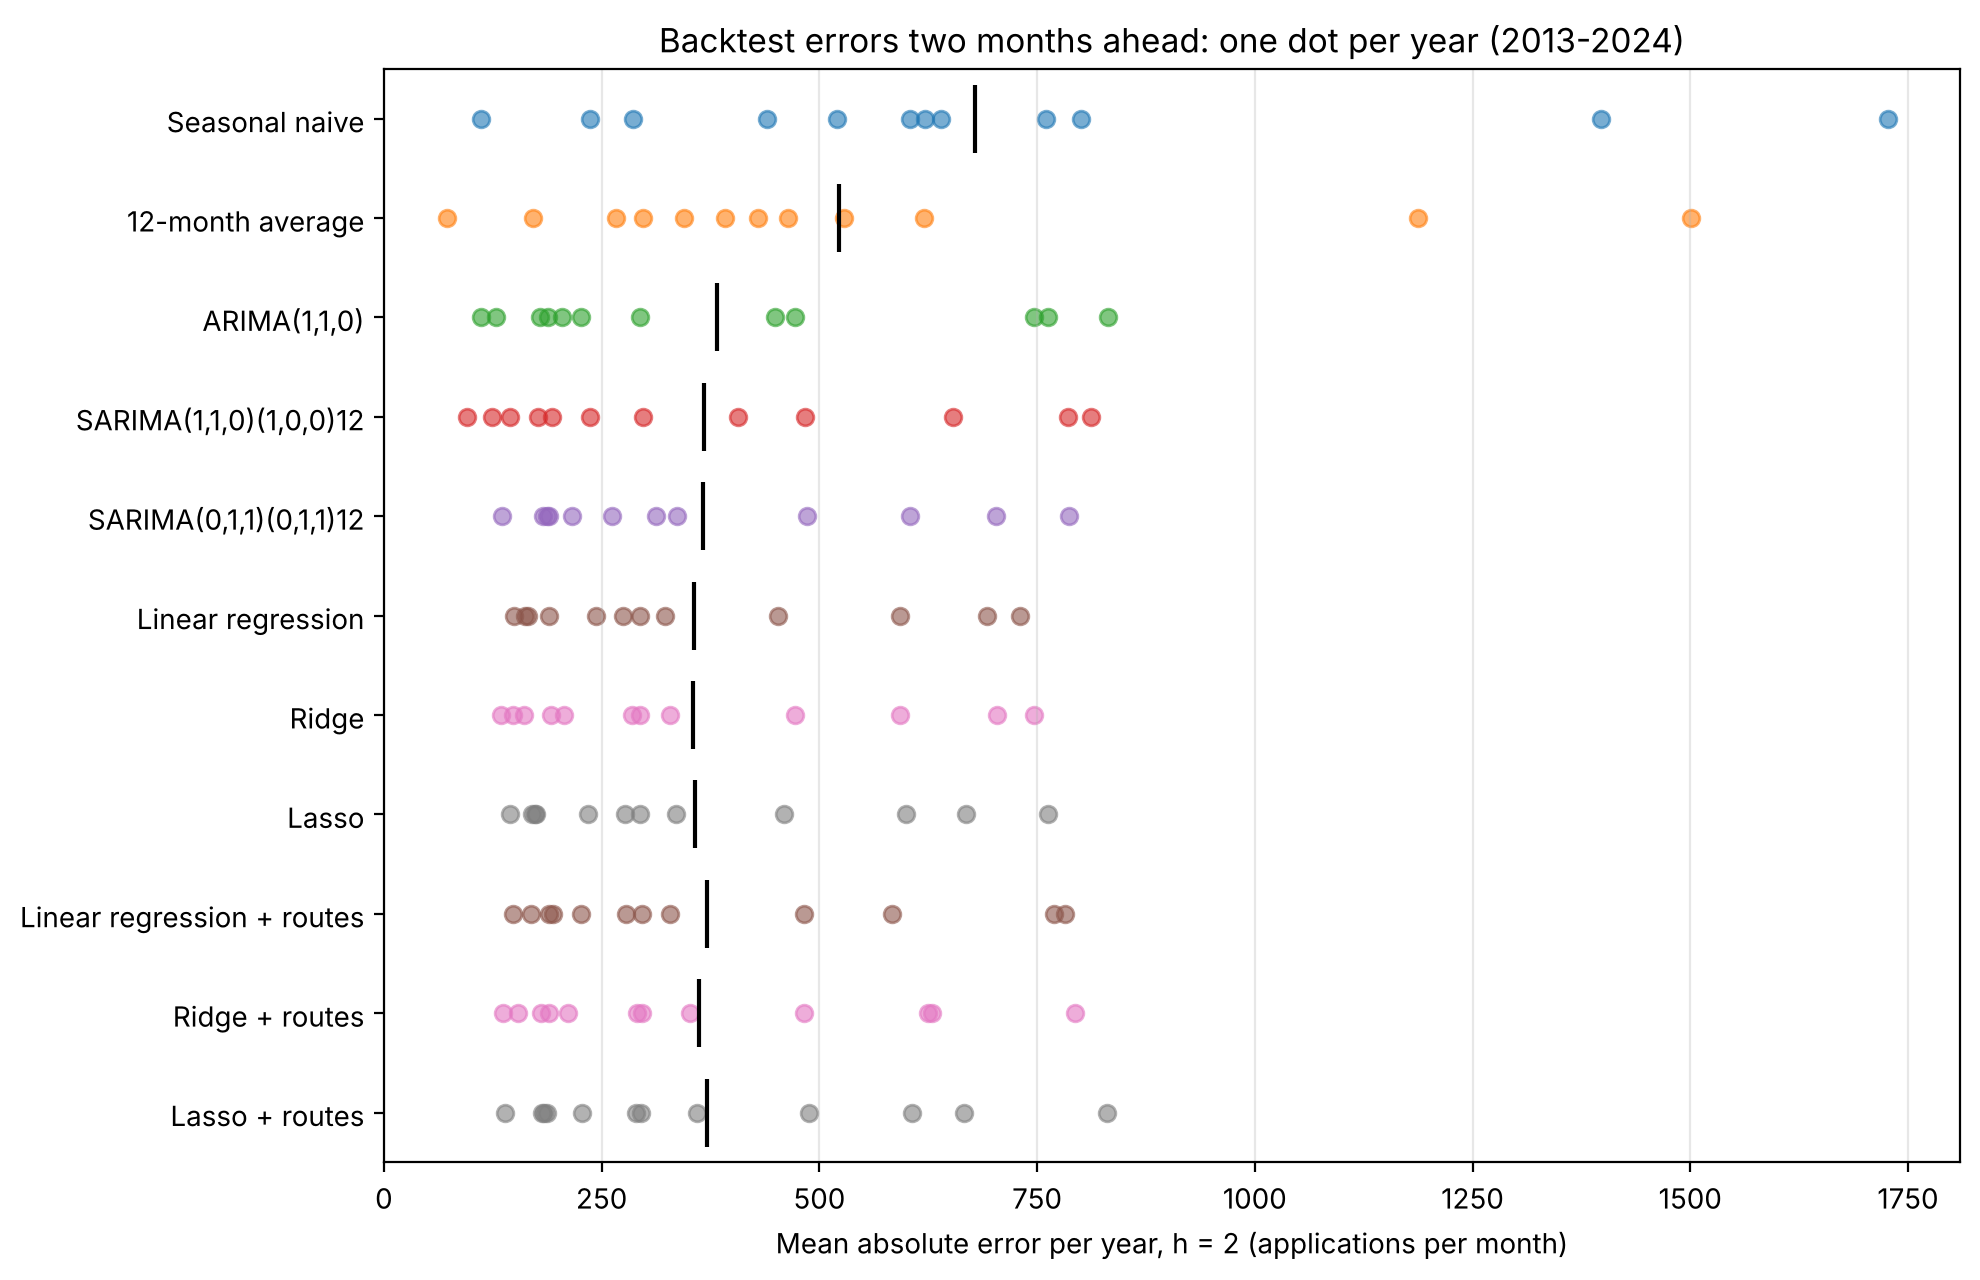

In [9]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for i, name in enumerate(model_order):
    errors_by_year = by_year[name]
    ax.scatter(errors_by_year, [i] * len(errors_by_year), alpha=0.6, color=colors[name])
    ax.scatter([errors_by_year.mean()], [i], marker="|", s=600, color="black")
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_order)
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.set_xlabel("Mean absolute error per year, h = 2 (applications per month)")
ax.set_title("Backtest errors two months ahead: one dot per year (2013-2024)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_errors_by_year_h2.png")
plt.show()

**What we see.**
- **Best model against best baseline:** Ridge has a lower MAE than the 12-month average in 8 of 12 years. The gap between their averages (167) is smaller than the spread across years (standard deviation 417 and 220). In the picture, the two dots far to the right of the 12-month average (about 1,190 and 1,500) are the years 2016 and 2015 (table above).
- **Best regression against best SARIMA:** Ridge is lower in 9 of 12 years, but the gap between the averages is only 11 persons, against a spread across years of about 220. Several of its wins are tiny (2019: 135 against 136; 2013: 207 against 216), and it loses in 2016, 2020 and 2021.
- In the picture, the six own-history models look almost the same: their averages (black bars) lie close together, between about 358 and 388. The three rows "+ routes" look very similar to the rows of the same models without the indicator.

**What this means for us.** The advantage of the own-history models over the simple rules is consistent, but it comes mostly from the years with big changes. Among the six own-history models, the differences are within the noise. When we choose the final model before the test period, a simpler model within the noise is a serious candidate (notebook 209, Step 7).

## 6. Errors over the horizon

How fast do the errors grow when we forecast further ahead? We plot the MAE of each model for $h = 1, 2, 3$.

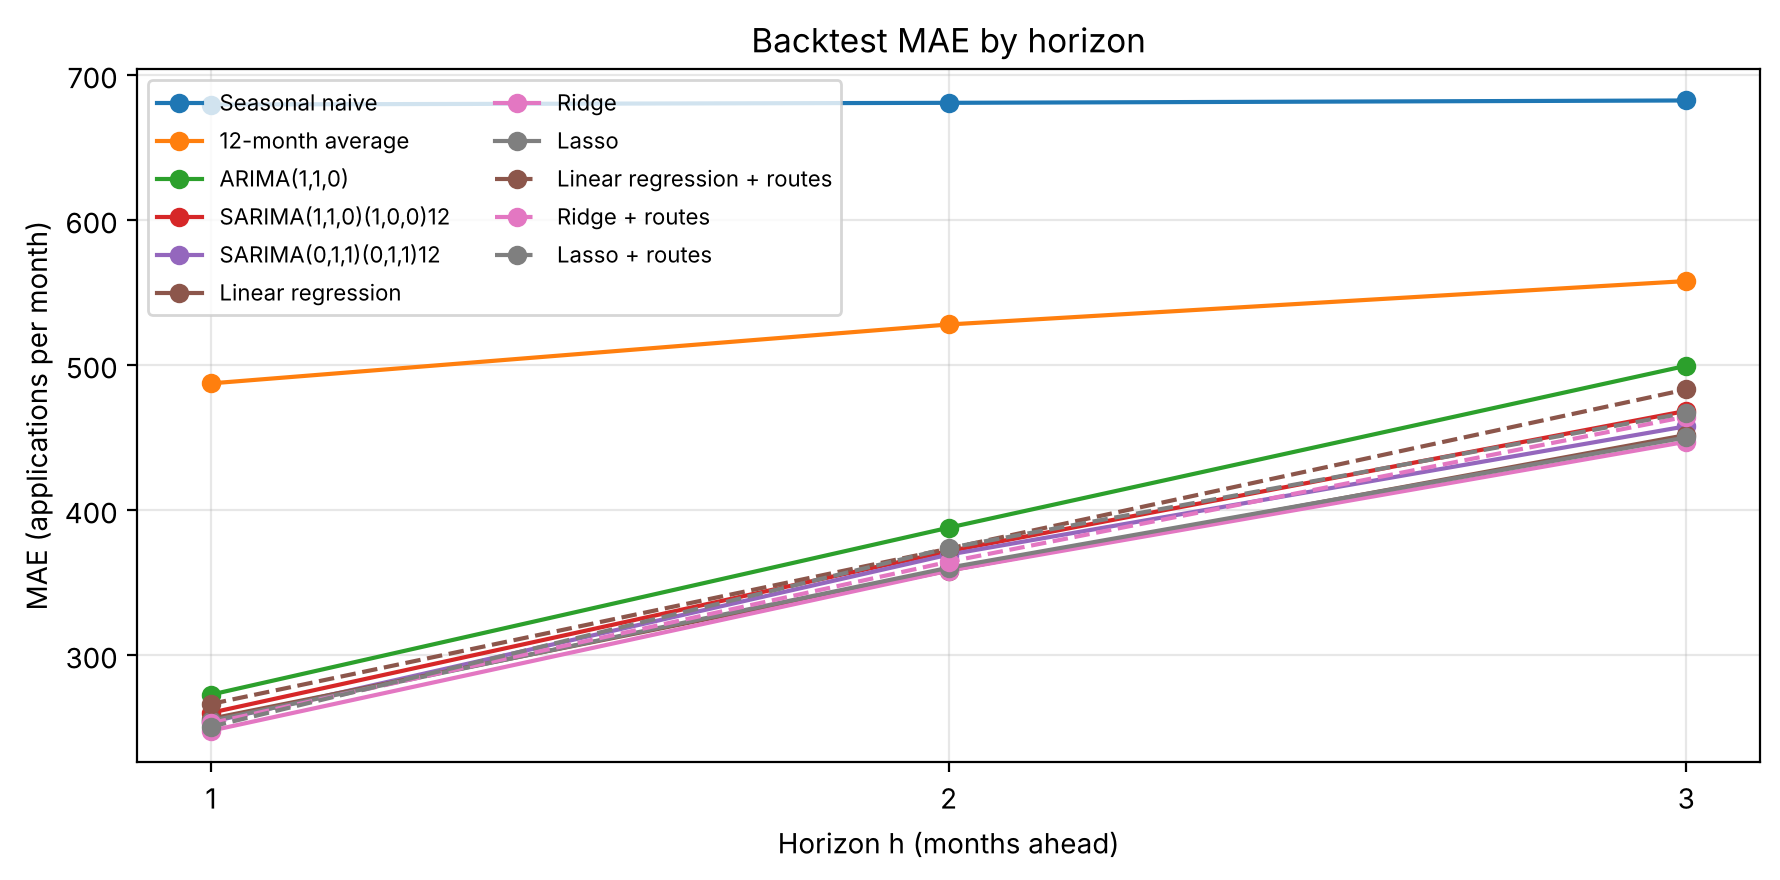

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, name in enumerate(model_order):
    one = errors[errors["model"] == name]
    style = "--" if name in indicator_models else "-"
    ax.plot(one["h"], one["MAE (persons)"], marker="o", linestyle=style, color=colors[name], label=name)
ax.set_xticks([1, 2, 3])
ax.set_xlabel("Horizon h (months ahead)")
ax.set_ylabel("MAE (applications per month)")
ax.set_title("Backtest MAE by horizon")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_mae_by_horizon.png")
plt.show()

**What we see.** For the six own-history models, the MAE grows steadily from about 250 at $h = 1$ to about 450 to 500 at $h = 3$, as expected: the further ahead, the less the recent months tell us (notebook 202). Ridge is lowest at every horizon (248, 358, 447), but the lines of the regressions and the SARIMA models almost overlap. The dashed lines (models with the route indicator) lie slightly above the lines of the same models without it, most visibly at $h = 3$. ARIMA(1,1,0), without a seasonal part, falls behind at $h = 3$ (499). The 12-month average grows more slowly (487 to 558), and the seasonal naive stays flat at about 680.

## 7. Does the route indicator help?

Our project plan adds the indicator block **one block at a time**: the models of `02c` are exactly those of `02b` plus two route features. So we compare each regression with its own "+ routes" version, on the same forecast months. We use the rule of our project plan: a change counts as a clear improvement only if it lowers the MAE by at least 10%.

In [11]:
rows = []
for name in regression_models:
    for h in [1, 2, 3]:
        without = errors[(errors["model"] == name) & (errors["h"] == h)].iloc[0]
        with_routes = errors[(errors["model"] == name + " + routes") & (errors["h"] == h)].iloc[0]
        rows.append({
            "model": name, "h": h,
            "MAE without routes": without["MAE (persons)"],
            "MAE with routes": with_routes["MAE (persons)"],
            "change in MAE (%)": 100 * (with_routes["MAE (persons)"] / without["MAE (persons)"] - 1),
            "RMSE (log) without": without["RMSE (log)"],
            "RMSE (log) with": with_routes["RMSE (log)"],
        })
indicator_effect = pd.DataFrame(rows).set_index(["model", "h"])
indicator_effect.to_csv("../output/tables/03_indicator_effect.csv")
indicator_effect.round(3)

MAE without routes  MAE with routes  change in MAE (%)  \
model             h                                                           
Linear regression 1             255.864          266.060              3.985   
                  2             358.007          373.149              4.229   
                  3             451.512          482.932              6.959   
Ridge             1             247.610          252.808              2.099   
                  2             357.949          364.084              1.714   
                  3             446.888          464.199              3.874   
Lasso             1             254.440          250.398             -1.589   
                  2             359.976          373.622              3.791   
                  3             449.834          466.779              3.767   

                     RMSE (log) without  RMSE (log) with  
model             h                                       
Linear regression 1               0.197            0.203  
                  2               0.278            0.282  
                  3               0.333            0.340  
Ridge             1               0.187            0.191  
                  2               0.279            0.281  
                  3               0.336            0.340  
Lasso             1               0.193            0.190  
                  2               0.281            0.285  
                  3               0.338            0.345

**What we see.**
- At the main horizon $h = 2$, all three regressions get **worse** with the route indicator: the MAE goes up by 1.7% (Ridge), 3.8% (Lasso) and 4.2% (linear regression). At $h = 3$ the loss is larger (3.8% to 7.0%).
- The only gain is Lasso at $h = 1$: 250.4 instead of 254.4 persons (−1.6%), and also a slightly lower RMSE (log) (0.190 against 0.193). Ridge and the linear regression are worse at $h = 1$ too.
- The RMSE (log) tells the same story: with the routes it is higher in 8 of the 9 cases.
- No change comes close to the 10% improvement of our success rule.

**What this means for us.** The route indicator, as we can use it at the cutoff, does not improve the forecasts. This fits what we found in `01b_preprocess_indicators.ipynb`: the change on the routes moved together with the change in applications in the same month and one month later (correlations 0.31 and 0.35), but hardly at all from two months on (0.08 or less). Because Frontex is published one month later than the target, the newest route month we may use lies at least $h + 1$ months before the forecast month, so the useful part of the signal arrives too late.

The same comparison year by year and by period, at the main horizon $h = 2$ (as in sections 4 and 5).

In [12]:
for name in regression_models:
    with_routes = name + " + routes"
    wins = (by_year[with_routes] < by_year[name]).sum()
    gap = by_year[name].mean() - by_year[with_routes].mean()
    print(f"{with_routes:27s} lower MAE than {name:18s} in {wins:2d} of {by_year.shape[0]} years | "
          f"gap of the averages {gap:6.1f} | spread across years {by_year[name].std():.0f}")
print()
by_period.pivot(index="model", columns="period", values="MAE (persons)").loc[regression_models + indicator_models, list(periods)].round(0)

Linear regression + routes  lower MAE than Linear regression  in  3 of 12 years | gap of the averages  -14.8 | spread across years 210
Ridge + routes              lower MAE than Ridge              in  2 of 12 years | gap of the averages   -6.2 | spread across years 220
Lasso + routes              lower MAE than Lasso              in  3 of 12 years | gap of the averages  -13.3 | spread across years 214



period,all backtest months,without 2015-16 and 2020,from 2022
model,,,
Linear regression,358.0,286.0,413.0
Ridge,358.0,282.0,415.0
Lasso,360.0,288.0,420.0
Linear regression + routes,373.0,291.0,412.0
Ridge + routes,364.0,292.0,436.0
Lasso + routes,374.0,297.0,431.0


In [13]:
# Year by year at h = 2: MAE of Ridge without and with the routes, and the difference
ridge_years = by_year[["Ridge", "Ridge + routes"]].copy()
ridge_years["with minus without"] = ridge_years["Ridge + routes"] - ridge_years["Ridge"]
ridge_years

,Ridge,Ridge + routes,with minus without
year,,,
2013,207.0,211.0,4.0
2014,472.0,482.0,10.0
2015,704.0,629.0,-75.0
2016,746.0,794.0,48.0
2017,161.0,180.0,19.0
2018,148.0,154.0,6.0
2019,135.0,137.0,2.0
2020,285.0,291.0,6.0
2021,192.0,190.0,-2.0


**What we see.**
- Year by year at $h = 2$, the versions with the routes are better in only 2 or 3 of the 12 years. The gaps of the averages (6 to 15 persons, in favour of the models *without* the routes) are small compared with the spread across years (about 210 to 220).
- For Ridge, the one year with a clear gain is **2015**, the start of the big crisis: 629 instead of 704 (−75). But in 2016 the routes made the forecasts worse (+48), and also in 2022 and 2023 (+23 and +32). In the other years the differences are small (between −2 and +19).
- Without 2015-16 and 2020, all three models are worse with the routes (291 to 297 against 282 to 288).

**What this means for us.** The loss from adding the routes is small and within the noise, but there is no sign of a gain either, except in 2015. One good year is not enough to choose a model (notebook 209: we look at all folds, not at the best one). Following our plan (one block at a time, keep it only if it helps), **we do not keep the route indicator in the final model**. We report this as a result: for forecasts two months ahead, the past of the Swiss series itself already contains what the routes tell us in time.

## 8. Our choice, before we look at the test period

Notebook 209 (Step 7): *choose before you test*, and write down the choice and the reason. The three best models at $h = 2$:

In [14]:
candidates = ["Ridge", "Linear regression", "SARIMA(0,1,1)(0,1,1)12"]
overview.loc[candidates]

,MAE h=1,MAE h=2,MAE h=3,RMSE log h=1,RMSE log h=2,RMSE log h=3
model,,,,,,
Ridge,248.0,358.0,447.0,0.187,0.279,0.336
Linear regression,256.0,358.0,452.0,0.197,0.278,0.333
"SARIMA(0,1,1)(0,1,1)12",254.0,369.0,458.0,0.191,0.274,0.328


**Our choice: the linear regression** (the one of `02b`, on the series' own past, one model per horizon).

**Reason.**
- Ridge has the lowest MAE, but the linear regression is practically equal: 358.0 against 357.9 persons at $h = 2$ (0.06 persons, section 7 table), with a slightly lower RMSE (log) (0.278 against 0.279). At $h = 1$ and $h = 3$, Ridge is a little better (248 against 256, 447 against 452 persons); our plan fixes $h = 2$ as the main horizon. SARIMA(0,1,1)(0,1,1)12 is about 3% worse by MAE at $h = 2$. All these differences are far smaller than the spread across years (about 220, section 5).
- Notebook 209, Step 7: if a simpler model is within the spread, it is a serious candidate. The linear regression is simpler than Ridge: it has no penalty, so it needs no choice of `alpha` inside each window, and its coefficients are easy to explain to a planner.
- The route indicator is not used (section 7).

**What we test, once.** The linear regression and, for the main comparison fixed in our project plan, the best simple baseline (the 12-month average). The test period is 2024-10 to 2026-09; the forecasts are made in the same way as in the backtest: at each origin, the model is fitted on all months known at that origin. We do not change this choice after seeing the test results.

# Part B: added after the test, the second model family

Sections 1 to 8 are the evaluation we made **before** the test; section 8 was saved on GitHub before `04_test.ipynb` was run (commit `c6a3976`, 17 November 2026). The sections below were added **after** the test period had been used once. They follow the same rules as Part A (backtest only, MAE in persons, main horizon $h = 2$, years as folds, the success rule of our plan), but they come too late to change the choice of section 8, and we do not let them: a model chosen after seeing the test would make the test result too optimistic (notebook 108b). Section 19 checks whether they would have changed it.

We now have **two model families**, each with the three regressions (linear regression, Ridge, Lasso):

1. **The series' own past** (`02b`): the family of our chosen model.
2. **Own past + indicators** (`02c`): each indicator alone (routes, neighbours, Mediterranean routes, conflict index), **all indicators together** (the model with the most data), and all indicators minus one block, which shows **which data lower the error the most** (section 13).

We also add a third simple rule, the **random walk** (`02`), the lag chosen inside each window (`02d`), and a second horizon, the total of the next 12 months (`02e`).

## 9. Load the forecasts of both families

The same two errors as in section 1, plus the **MSE in logs** (the square of the RMSE), the error the models minimise when they are fitted.

In [15]:
def read(path):
    data = pd.read_csv(path)
    data["month"] = pd.to_datetime(data["month"])
    data["origin"] = pd.to_datetime(data["origin"])
    return data

cols = ["model", "origin", "month", "h", "forecast_log", "actual_log", "forecast", "actual"]
base = pd.concat([read("../data/processed/backtest_forecasts.csv")[cols],             # simple rules (with the random walk), (S)ARIMA
                  read("../data/processed/backtest_forecasts_regression.csv")[cols],  # family 1: the series' own past
                  read("../data/processed/backtest_forecasts_indicator.csv")[cols]],  # family 2, Part A: + routes
                 ignore_index=True)
extra = read("../data/processed/backtest_forecasts_extra.csv")                        # family 2, Part B
lag_choice = read("../data/processed/backtest_forecasts_lag_choice.csv")

forecasts_b = pd.concat([base, extra[cols], lag_choice[cols]], ignore_index=True)
forecasts_b["abs_error"] = (forecasts_b["actual"] - forecasts_b["forecast"]).abs()
forecasts_b["sq_error_log"] = (forecasts_b["actual_log"] - forecasts_b["forecast_log"]) ** 2

counts = forecasts_b.groupby(["model", "h"]).size().unstack()
print("Models:", forecasts_b["model"].nunique(), "| forecasts per model and horizon:", counts.drop_duplicates().to_dict("records"))
print("Same forecast months for all models:",
      forecasts_b.groupby(["model", "h"])["month"].apply(lambda m: tuple(sorted(m))).groupby("h").nunique().eq(1).all())

Models: 39 | forecasts per model and horizon: [{1: 141, 2: 140, 3: 139}]
Same forecast months for all models: True


## 10. Errors of all models

`error_table` is the function of section 2.

In [16]:
simple_rules = ["Seasonal naive", "12-month average", "Random walk"]
indicators = ["routes", "neighbours", "Med routes", "conflict"]
single_models = [f"{m} + {b}" for b in indicators for m in regression_models]
all_models = [f"{m} + all indicators" for m in regression_models]
drop_models = [f"{m} + all but {b}" for b in indicators for m in regression_models]
lag_models = sorted(lag_choice["model"].unique())
model_order_b = simple_rules + sarima_models + regression_models + single_models + all_models + drop_models + lag_models

errors_b = error_table(forecasts_b)
errors_b["MSE (log)"] = errors_b["RMSE (log)"] ** 2
mae = errors_b.pivot(index="model", columns="h", values="MAE (persons)").loc[model_order_b].round(0)
mae.columns = [f"MAE h={h}" for h in mae.columns]
mse = errors_b.pivot(index="model", columns="h", values="MSE (log)").loc[model_order_b].round(4)
mse.columns = [f"MSE log h={h}" for h in mse.columns]
overview_b = pd.concat([mae, mse], axis=1)
overview_b.to_csv("../output/tables/03_extra_errors.csv")
overview_b

,MAE h=1,MAE h=2,MAE h=3,MSE log h=1,MSE log h=2,MSE log h=3
model,,,,,,
Seasonal naive,679.0,681.0,682.0,0.1901,0.1911,0.1921
12-month average,487.0,528.0,558.0,0.1004,0.1168,0.1311
Random walk,259.0,379.0,487.0,0.0379,0.0832,0.1283
"ARIMA(1,1,0)",272.0,388.0,499.0,0.0427,0.0854,0.1303
"SARIMA(1,1,0)(1,0,0)12",260.0,371.0,468.0,0.0395,0.0797,0.1206
"SARIMA(0,1,1)(0,1,1)12",254.0,369.0,458.0,0.0366,0.0752,0.1078
Linear regression,256.0,358.0,452.0,0.0390,0.0774,0.1112
Ridge,248.0,358.0,447.0,0.0350,0.0778,0.1130
Lasso,254.0,360.0,450.0,0.0371,0.0787,0.1142


**What we see.**
- All 39 models have the same 141, 140 and 139 forecast months, so the comparison is fair (notebook 209).
- **The random walk is a strong simple rule:** 379 persons at $h = 2$, far better than the 12-month average (528) and close to the own-history models (358 to 371).
- **With all indicators**, Ridge reaches 341 at $h = 2$, as low as Ridge with the Mediterranean routes alone (341); the lowest of all is Ridge with all indicators but the neighbours (339).
- **Without a penalty, more data makes things worse:** the linear regression with all indicators misses by 379 at $h = 2$ against 358 on the own past (288 against 256 at $h = 1$). With 22 features and fewer than 200 training rows it overfits (notebook 105). Lasso is in between (356).
- The MSE (log) gives the same picture at $h = 2$: Ridge + all indicators 0.0735, the linear regression 0.0774.

## 11. A third simple rule: the last known month

Our plan's main comparison is the best simple baseline against the best model, at $h = 2$ (section 3, Johannes' feedback). With the random walk as a third simple rule, which one is the best simple baseline, and does our chosen model still meet the success rule (at least 10% lower MAE and a win in most backtest years)?

In [17]:
h2_b = errors_b[errors_b["h"] == 2].set_index("model")
h2_all_b = forecasts_b[forecasts_b["h"] == 2].copy()
h2_all_b["year"] = h2_all_b["month"].dt.year
by_year_b = h2_all_b.groupby(["year", "model"])["abs_error"].mean().reset_index()
by_year_b = by_year_b.pivot(index="year", columns="model", values="abs_error")[model_order_b].round(0)
by_year_b.columns.name = None

def compare(a, b):
    # a against b at h = 2: change in MAE, wins year by year, gap of the averages, spread across years
    change = 100 * (h2_b.loc[a, "MAE (persons)"] / h2_b.loc[b, "MAE (persons)"] - 1)
    wins = int((by_year_b[a] < by_year_b[b]).sum())
    return {"model": a, "against": b, "MAE": round(h2_b.loc[a, "MAE (persons)"]), "MAE against": round(h2_b.loc[b, "MAE (persons)"]),
            "change in MAE (%)": round(change, 1), "years won (of 12)": wins,
            "gap of the yearly averages": round(by_year_b[b].mean() - by_year_b[a].mean()),
            "spread across years (std of b)": round(by_year_b[b].std()),
            "success rule met": bool(change <= -10 and wins > by_year_b.shape[0] / 2)}

rw_table = pd.DataFrame([compare("Linear regression", b) for b in simple_rules]).set_index("against")
rw_table.to_csv("../output/tables/03_random_walk.csv")
rw_table

,model,MAE,MAE against,change in MAE (%),years won (of 12),gap of the yearly averages,spread across years (std of b),success rule met
against,,,,,,,,
Seasonal naive,Linear regression,358,681,-47.4,11,323,467,True
12-month average,Linear regression,358,528,-32.2,9,167,417,True
Random walk,Linear regression,358,379,-5.4,7,19,237,False


**What we see.**
- Against our two planned simple rules, the chosen linear regression meets the success rule clearly: 47% and 32% lower MAE, better in 11 and 9 of the 12 years.
- **Against the random walk it would not:** only 5.4% lower MAE (358 against 379) and better in 7 of 12 years. The gap of the yearly averages (19 persons) is small compared with the spread across years (237).

**What this means for us.** Our main result holds against the simple rules we fixed in advance. But in the backtest, most of the gain over the 12-month average comes from starting at the **last known month**, which the 12-month average does not do; the regression adds the seasonal pattern on top. We report this honestly: the random walk was not in our plan, and adding it after the test does not change our choice. How it does on the test months is reported in `04_test.ipynb`, section 8.

## 12. Does each indicator help on its own?

As for the route indicator in section 7: each regression against the same regression without indicators, on the same forecast months, at all horizons, by MAE and by MSE (log). Negative = lower error with the indicator. The last rows are the models with **all indicators**, and the models of `02d` (Ridge, lag chosen in each window), compared with Ridge.

In [18]:
def effect_row(a, b, h, **info):
    # model a (with indicators) against model b (without), at horizon h
    e_a = errors_b[(errors_b["model"] == a) & (errors_b["h"] == h)].iloc[0]
    e_b = errors_b[(errors_b["model"] == b) & (errors_b["h"] == h)].iloc[0]
    return {**info, "h": h, "MAE without": e_b["MAE (persons)"], "MAE with": e_a["MAE (persons)"],
            "change in MAE (%)": 100 * (e_a["MAE (persons)"] / e_b["MAE (persons)"] - 1),
            "change in MSE log (%)": 100 * (e_a["MSE (log)"] / e_b["MSE (log)"] - 1)}

rows = []
for block in indicators + ["all indicators"]:
    for name in regression_models:
        for h in [1, 2, 3]:
            rows.append(effect_row(f"{name} + {block}", name, h, block=block, model=name))
for name in lag_models:
    for h in [1, 2, 3]:
        rows.append(effect_row(name, "Ridge", h, block=name.replace("Ridge + ", ""), model="Ridge"))
effect = pd.DataFrame(rows)
effect.to_csv("../output/tables/03_extra_effect.csv", index=False)
effect.pivot_table(index=["block", "model"], columns="h", values=["change in MAE (%)", "change in MSE log (%)"],
                   sort=False).round(1)

change in MAE (%)            \
h                                                         1    2    3   
block                   model                                           
routes                  Linear regression               4.0  4.2  7.0   
                        Ridge                           2.1  1.7  3.9   
                        Lasso                          -1.6  3.8  3.8   
neighbours              Linear regression               3.3  0.9  3.1   
                        Ridge                          -3.0  2.3  2.7   
                        Lasso                          -2.2  3.4 -0.0   
Med routes              Linear regression               2.6 -1.3  0.8   
                        Ridge                          -3.0 -4.8 -2.9   
                        Lasso                          -2.8 -4.0 -1.9   
conflict                Linear regression               3.1  0.4  2.4   
                        Ridge                           0.4 -1.4 -0.5   
                        Lasso                           2.0  0.4 -0.6   
all indicators          Linear regression              12.7  5.8  6.8   
                        Ridge                          -0.8 -4.7  1.2   
                        Lasso                          -2.1 -1.2  1.3   
Med routes (lag chosen) Ridge                          -2.2 -3.4 -1.5   
conflict (lag chosen)   Ridge                           3.8  2.8  1.1   
neighbours (lag chosen) Ridge                          -0.4  2.3  5.6   

                                          change in MSE log (%)             
h                                                             1    2     3  
block                   model                                               
routes                  Linear regression                   5.3  2.4   3.9  
                        Ridge                               3.8  1.5   2.6  
                        Lasso                              -2.8  3.3   4.0  
neighbours              Linear regression                   5.6  2.6   6.8  
                        Ridge                              -1.8  4.3   4.6  
                        Lasso                              -0.3  6.4   2.1  
Med routes              Linear regression                  -5.2 -0.6   0.8  
                        Ridge                              -5.8 -5.1  -2.7  
                        Lasso                              -9.3 -4.5  -1.3  
conflict                Linear regression                   2.3  1.2   2.5  
                        Ridge                               1.7 -1.6  -0.0  
                        Lasso                               1.8  0.3  -0.4  
all indicators          Linear regression                  11.8  3.7  10.5  
                        Ridge                              -2.3 -5.5   0.9  
                        Lasso                              -5.9  0.2   3.0  
Med routes (lag chosen) Ridge                              -3.0 -4.6  -2.0  
conflict (lag chosen)   Ridge                               3.1  4.4   1.2  
neighbours (lag chosen) Ridge                               5.9  4.1   6.9

**What we see** (at $h = 2$).
- **Only the Mediterranean routes lower the error on their own**, for Ridge and Lasso: −4.8% and −4.0% MAE, −5.1% and −4.5% MSE (log). For the linear regression the gain is small (−1.3% MAE).
- The Frontex routes (Part A) and the neighbours make all three models worse (+0.9% to +4.2% MAE, up to +6.4% MSE). The conflict index changes little.
- **All indicators together:** Ridge −4.7% MAE and −5.5% MSE, about as good as the Mediterranean routes alone; Lasso practically unchanged (−1.2% MAE, +0.2% MSE); the linear regression clearly worse (+5.8% MAE, +12.7% at $h = 1$). More data only helps with a penalty that keeps the coefficients small.
- No change comes close to the 10% of our success rule.

## 13. Which data lower the error the most? All indicators, minus one block at a time

Adding one block at a time (section 12) does not show whether a block still helps **when the others are already in the model**: the routes and the Mediterranean routes, for example, are almost the same numbers. So we start from the model with all indicators and remove one block at a time (`02c`, Part B). If the MSE rises when a block is removed, the block was lowering the error; if it falls, the model is better without it.

In [19]:
rows = []
for name in regression_models:
    for removed in indicators:
        for h in [1, 2, 3]:
            full = errors_b[(errors_b["model"] == f"{name} + all indicators") & (errors_b["h"] == h)].iloc[0]
            drop = errors_b[(errors_b["model"] == f"{name} + all but {removed}") & (errors_b["h"] == h)].iloc[0]
            rows.append({"model": name, "block removed": removed, "h": h,
                         "MSE (log) with all": full["MSE (log)"], "MSE (log) without the block": drop["MSE (log)"],
                         "rise in MSE when removed (%)": 100 * (drop["MSE (log)"] / full["MSE (log)"] - 1),
                         "rise in MAE when removed (%)": 100 * (drop["MAE (persons)"] / full["MAE (persons)"] - 1)})
contribution = pd.DataFrame(rows)
contribution.to_csv("../output/tables/03_block_contribution.csv", index=False)

c2 = contribution[contribution["h"] == 2]
print("h = 2: rise in the error when one block is removed from all indicators (positive = the block was helping)")
pd.concat({"rise in MSE (log), %": c2.pivot(index="block removed", columns="model", values="rise in MSE when removed (%)"),
           "rise in MAE, %": c2.pivot(index="block removed", columns="model", values="rise in MAE when removed (%)")},
          axis=1).loc[indicators].round(1)

h = 2: rise in the error when one block is removed from all indicators (positive = the block was helping)


rise in MSE (log), %                         rise in MAE, %  \
model                        Lasso Linear regression Ridge          Lasso   
block removed                                                               
routes                         2.7               0.0   2.3           -0.8   
neighbours                    -5.5              -5.3  -1.0           -3.0   
Med routes                     6.2               5.0   9.9            5.5   
conflict                      -1.7              -2.2   1.1           -0.3   

                                       
model         Linear regression Ridge  
block removed                          
routes                     -4.9   0.3  
neighbours                 -1.5  -0.6  
Med routes                  1.7   7.7  
conflict                   -0.5   0.5

Lasso gives its own answer (`02c`, section B7): at how many of the backtest origins ($h = 2$) does it keep each indicator feature (coefficient not 0)?

In [20]:
pd.read_csv("../output/tables/02c_lasso_kept.csv", index_col="feature")

,block,share of origins kept,mean coefficient
feature,,,
routes_change_last_month,routes,0.31,0.002
routes_change_3_months,routes,0.51,-0.027
neighbours_change_last_month,neighbours,0.33,0.002
neighbours_change_3_months,neighbours,0.44,-0.015
med_change_last_month,Med routes,0.60,0.010
med_change_3_months,Med routes,0.88,0.062
conflict_3_months,conflict,0.21,0.004
conflict_6_months,conflict,0.33,-0.005


**What we see.**
- **The Mediterranean routes are the data that lower the error the most.** Removing them from the model with all indicators raises the MSE (log) at $h = 2$ by 9.9% for Ridge, 6.2% for Lasso and 5.0% for the linear regression (the MAE by 7.7%, 5.5% and 1.7%). They are the most useful block at all three horizons.
- **The neighbours hurt:** without them the MSE falls (−1.0% to −5.5% at $h = 2$), so the models are better without them. This fits `01b` (section B8): applications in the neighbouring countries move in the same month as in Switzerland, and at the cutoff we only know them up to $t-1$.
- **The Frontex routes and the conflict index add little once the Mediterranean routes are in** (between −2.2% and +2.7%). The routes carry almost the same numbers as the Mediterranean routes, one month later.
- **Lasso agrees:** it keeps the 3-month change of the Mediterranean routes at 88% of the origins, the conflict features at only 21% and 33%.

**What this means for us.** If a planner wanted one extra data source, it would be the monthly arrivals on the Mediterranean routes (UNHCR), because they arrive one month earlier than the other data. The other sources mostly add noise. Whether this ranking holds on new months is shown, for information, in `04_test.ipynb` (section 8).

## 14. Year by year at $h = 2$, and the success rule

As in section 5 (notebook 209): the years are our folds. For every model with indicators: in how many of the 12 years is it better than the same model without them, and is the gap of the averages large compared with the spread across years? The success rule of our plan, fixed before modelling, asks for at least 10% lower MAE **and** a win in most years.

In [21]:
pairs = ([(f"{m} + {b}", m) for b in indicators + ["all indicators"] for m in regression_models]
         + [(m, "Ridge") for m in lag_models])
year_table = pd.DataFrame([compare(a, b) for a, b in pairs]).set_index("model")
by_year_b.to_csv("../output/tables/03_extra_by_year_h2.csv")
year_table.drop(columns=["against"])

,MAE,MAE against,change in MAE (%),years won (of 12),gap of the yearly averages,spread across years (std of b),success rule met
model,,,,,,,
Linear regression + routes,373,358,4.2,3,-15,210,False
Ridge + routes,364,358,1.7,2,-6,220,False
Lasso + routes,374,360,3.8,3,-13,214,False
Linear regression + neighbours,361,358,0.9,4,-3,210,False
Ridge + neighbours,366,358,2.3,4,-8,220,False
Lasso + neighbours,372,360,3.4,2,-12,214,False
Linear regression + Med routes,353,358,-1.3,7,5,210,False
Ridge + Med routes,341,358,-4.8,8,17,220,False
Lasso + Med routes,346,360,-4.0,6,15,214,False


**What we see.**
- The best models with indicators win in **8 of 12 years** against the same model without them: Ridge + Med routes, Ridge + all indicators, Ridge + conflict, and Ridge + Med routes with the lag chosen. The routes and the neighbours win in only 2 to 4 years, the linear regression with all indicators in 4.
- **But the gaps are small compared with the spread across years:** at most 17 persons (Ridge + Med routes, Ridge + all indicators) against a spread of about 220.
- **No model meets the success rule** (at least 10% lower MAE and a win in most years): the MAE gains are at most 4.8%.

**What this means for us.** As for the route indicator in section 7, the indicators do not give a clear improvement. We tried more than 30 variants after the test, so the best of them looks better than it would on new data (notebook 108b): we treat −4.8% as a hint, not as a result.

## 15. Without the crisis periods

As in section 4: all backtest months, without 2015-16 and 2020, and from 2022 only ($h = 2$).

In [22]:
month_b = forecasts_b["month"]
crisis_b = ((month_b >= "2015-01-01") & (month_b <= "2016-12-01")) | ((month_b >= "2020-01-01") & (month_b <= "2020-12-01"))
periods_b = {"all backtest months": forecasts_b, "without 2015-16 and 2020": forecasts_b[~crisis_b],
             "from 2022": forecasts_b[month_b >= "2022-01-01"]}
rows = []
for period_name, data in periods_b.items():
    table = error_table(data[data["h"] == 2])
    table["period"] = period_name
    rows.append(table)
by_period_b = pd.concat(rows)
show = ["Random walk"] + regression_models + [f"Ridge + {b}" for b in indicators] + all_models + lag_models
by_period_b.pivot(index="model", columns="period", values="MAE (persons)").loc[show, list(periods_b)].round(0)

period,all backtest months,without 2015-16 and 2020,from 2022
model,,,
Random walk,379.0,309.0,488.0
Linear regression,358.0,286.0,413.0
Ridge,358.0,282.0,415.0
Lasso,360.0,288.0,420.0
Ridge + routes,364.0,292.0,436.0
Ridge + neighbours,366.0,289.0,429.0
Ridge + Med routes,341.0,270.0,403.0
Ridge + conflict,353.0,278.0,412.0
Linear regression + all indicators,379.0,280.0,369.0


**What we see.** Without 2015-16 and 2020, Ridge + Med routes (270) and Ridge + all indicators (271) are lowest, against 282 for Ridge and 286 for the linear regression. From 2022, the linear regression with all indicators is lowest (369 against 413 for the linear regression, −11%), then Ridge + all indicators (380), but over only 33 months and after being the worst over the whole backtest. The neighbours and the conflict index with the lag chosen are worse than Ridge in every period.

## 16. The two model families side by side

**Model 1** is our choice of section 8: the linear regression on the series' own past. **Model 2** is the best model with **all indicators**, chosen with code by its backtest MAE at $h = 2$ among the three regressions, exactly as section 3 picks the best model (nothing chosen by hand). We save both names for `04_test.ipynb`, section 8.

In [23]:
model_1 = "Linear regression"                                 # chosen before the test (section 8)
model_2 = h2_b.loc[all_models, "MAE (persons)"].idxmin()      # all indicators, best backtest MAE at h = 2
own_2 = model_2.split(" + ")[0]                               # the same regression without indicators
pd.DataFrame({"family": ["own past", "all indicators"], "model": [model_1, model_2]}).to_csv(
    "../output/tables/03_two_models.csv", index=False)
print("Model 1:", model_1, "| Model 2:", model_2)
print()
print(overview_b.loc[[model_1, own_2, model_2]])
pd.DataFrame([compare(model_2, model_1), compare(model_2, own_2), compare(model_1, "Random walk"),
              compare(model_2, "Random walk")]).set_index("model")

Model 1: Linear regression | Model 2: Ridge + all indicators

                        MAE h=1  MAE h=2  MAE h=3  MSE log h=1  MSE log h=2  \
model                                                                         
Linear regression         256.0    358.0    452.0       0.0390       0.0774   
Ridge                     248.0    358.0    447.0       0.0350       0.0778   
Ridge + all indicators    246.0    341.0    452.0       0.0343       0.0735   

                        MSE log h=3  
model                                
Linear regression            0.1112  
Ridge                        0.1130  
Ridge + all indicators       0.1140  


,against,MAE,MAE against,change in MAE (%),years won (of 12),gap of the yearly averages,spread across years (std of b),success rule met
model,,,,,,,,
Ridge + all indicators,Linear regression,341,358,-4.7,7,17,210,False
Ridge + all indicators,Ridge,341,358,-4.7,8,17,220,False
Linear regression,Random walk,358,379,-5.4,7,19,237,False
Ridge + all indicators,Random walk,341,379,-9.8,8,36,237,False


**What we see.**
- **Model 2 is Ridge with all indicators:** 341 persons at $h = 2$ against 358 for model 1, 4.7% lower MAE and 5.0% lower MSE (log) (0.0735 against 0.0774), better in 7 of 12 years. Against Ridge without indicators the gain is the same (−4.7%, 8 of 12 years).
- At $h = 1$ model 2 is a little better (246 against 256); at $h = 3$ it is not (452 against 452), and its MSE (log) is slightly higher (0.1140 against 0.1112).
- Against the random walk, model 2 gains 9.8% and wins in 8 of 12 years, just short of the 10% that model 1 misses more clearly (−5.4%).
- The gap of the yearly averages (17 persons) is small compared with the spread across years (about 210 to 220).

**What this means for us.** The model with the most data is a little better in the backtest at $h = 2$, but not by the 10% our plan requires, and not at $h = 3$. The two families are within the noise of each other.

## 17. The pictures

First: the change in MAE at $h = 2$ for every model with indicators, against the same model without them (bars to the left: lower error; the dashed line marks the 10% of our success rule). Second: which blocks the all-indicator models need (section 13). Third: the random walk and the two models year by year.

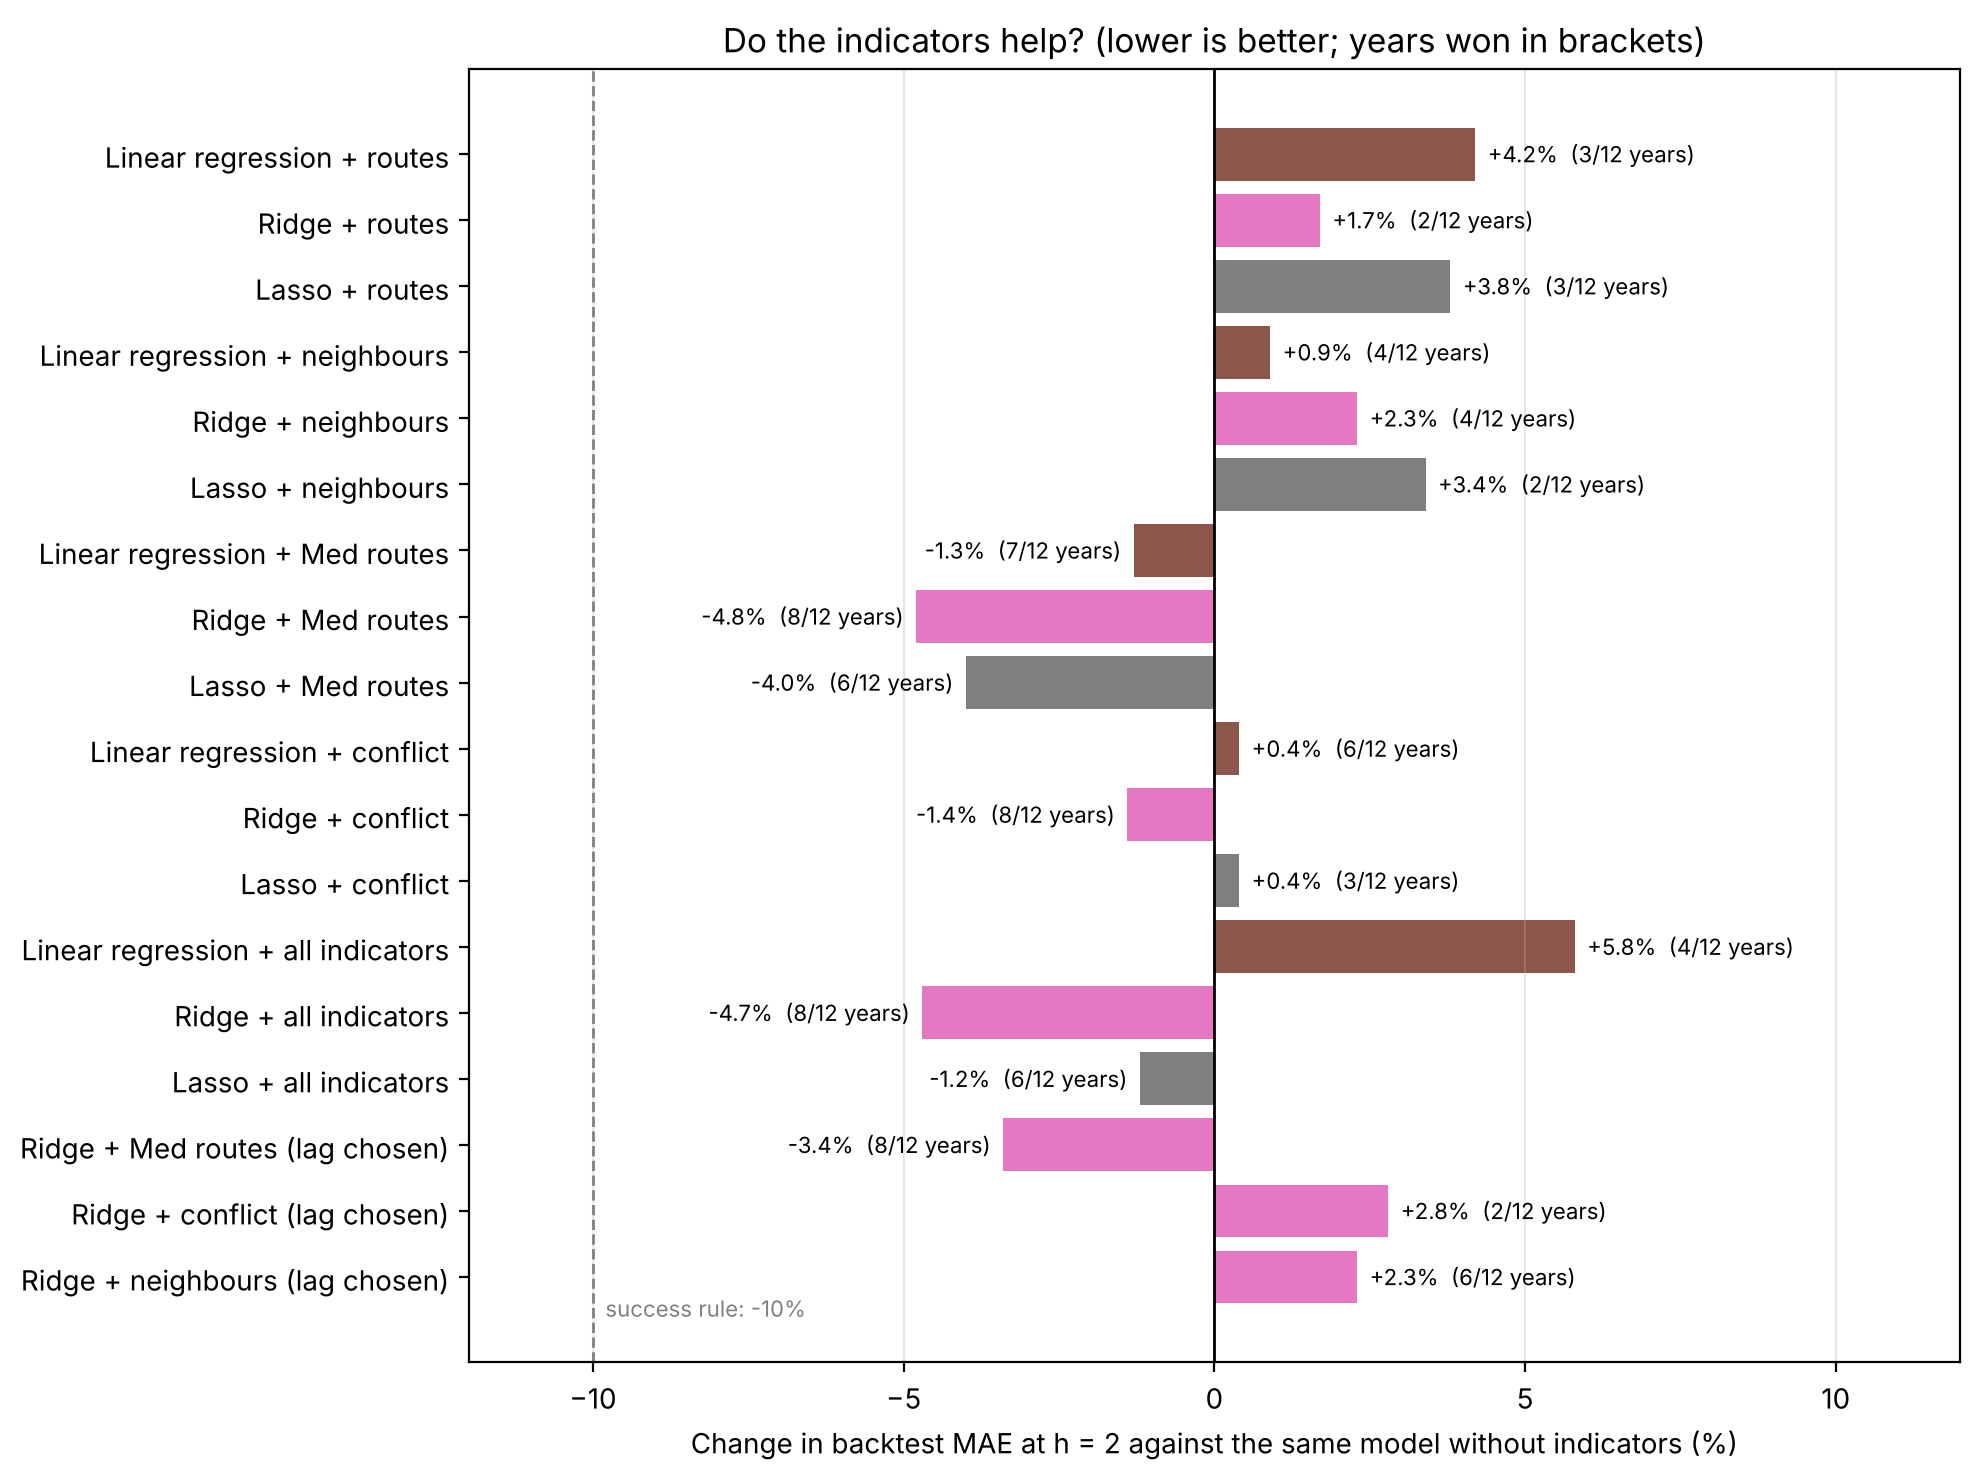

In [24]:
labels, values, colours = [], [], []
for a, b in pairs:
    labels.append(a)
    values.append(year_table.loc[a, "change in MAE (%)"])
    colours.append(plt.cm.tab10(regression_models.index(b) + 5))     # same colours as in sections 5 and 6

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(range(len(labels)), values, color=colours)
for i, a in enumerate(labels):
    ax.text(values[i] + (0.2 if values[i] >= 0 else -0.2), i, f"{values[i]:+.1f}%  ({year_table.loc[a, 'years won (of 12)']}/12 years)",
            va="center", ha="left" if values[i] >= 0 else "right", fontsize=8)
ax.axvline(0, color="black", linewidth=1)
ax.axvline(-10, color="grey", linestyle="--", linewidth=1)
ax.text(-9.8, len(labels) - 0.4, "success rule: -10%", color="grey", fontsize=8)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(-12, 12)
ax.set_xlabel("Change in backtest MAE at h = 2 against the same model without indicators (%)")
ax.set_title("Do the indicators help? (lower is better; years won in brackets)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_extra_data_effect_h2.png")
plt.show()

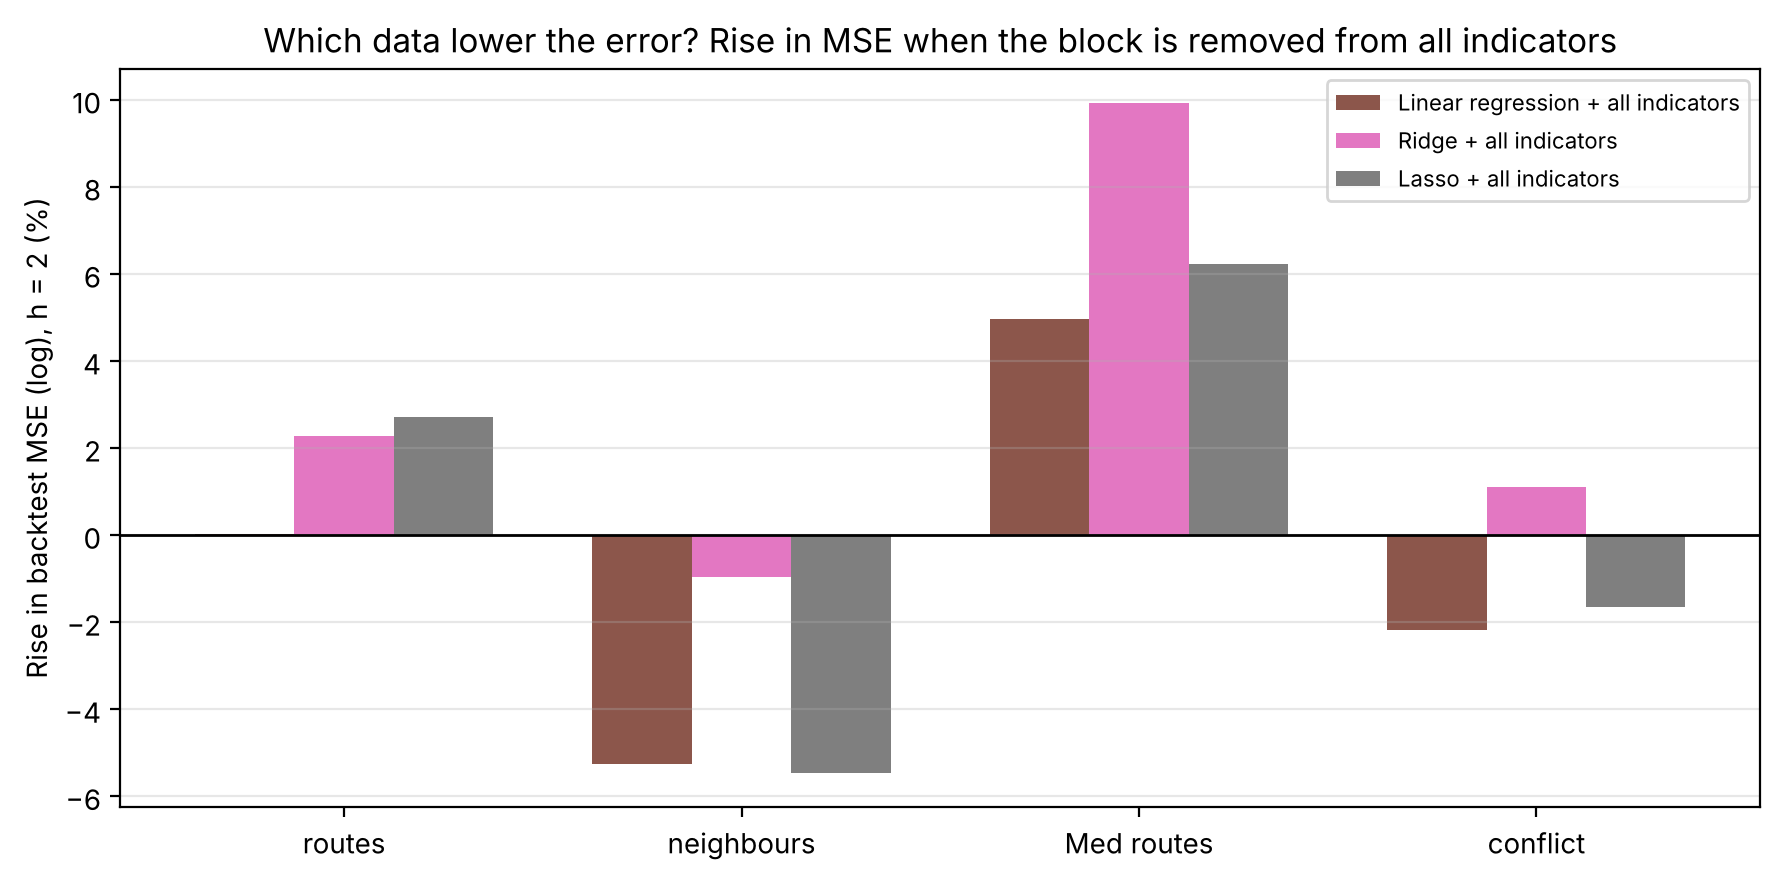

In [25]:
table = c2.pivot(index="block removed", columns="model", values="rise in MSE when removed (%)").loc[indicators, regression_models]
width = 0.25
fig, ax = plt.subplots(figsize=(9, 4.5))
for j, name in enumerate(regression_models):
    ax.bar(np.arange(len(indicators)) + (j - 1) * width, table[name], width, color=colors[name], label=name + " + all indicators")
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(range(len(indicators)))
ax.set_xticklabels(indicators)
ax.set_ylabel("Rise in backtest MSE (log), h = 2 (%)")
ax.set_title("Which data lower the error? Rise in MSE when the block is removed from all indicators")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_block_contribution_h2.png")
plt.show()

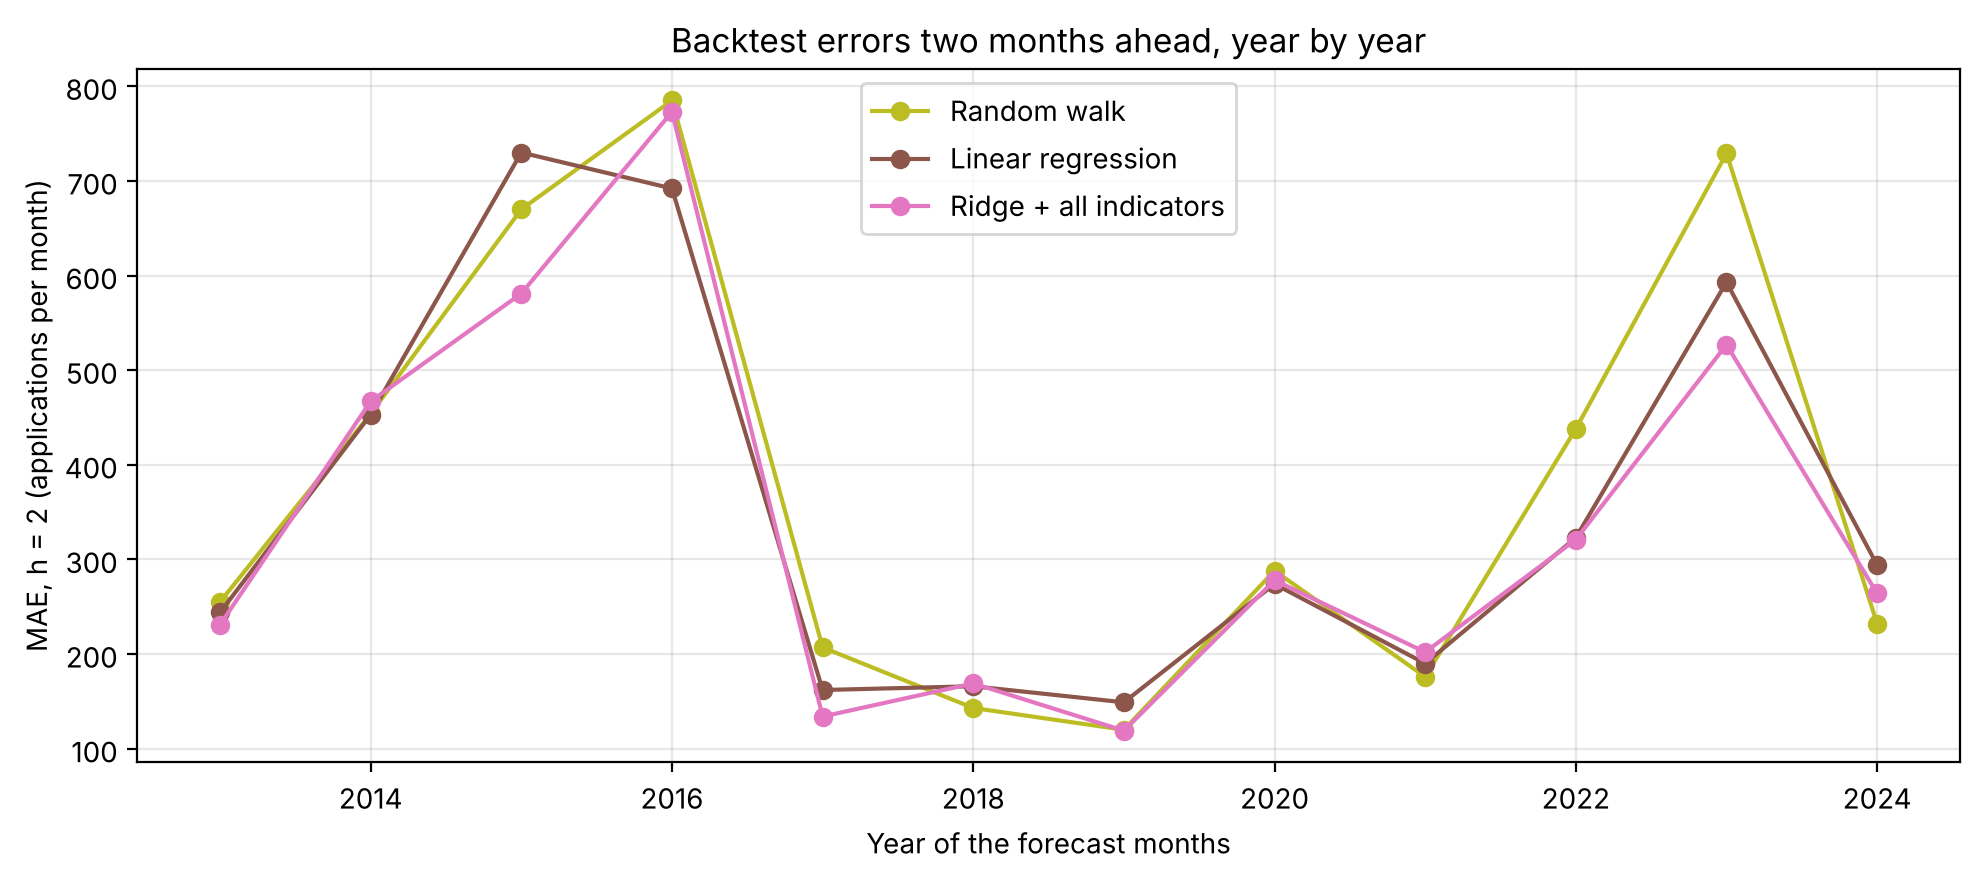

In [26]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, colour in [("Random walk", plt.cm.tab10(8)), (model_1, plt.cm.tab10(5)), (model_2, plt.cm.tab10(6))]:
    ax.plot(by_year_b.index, by_year_b[name], marker="o", color=colour, label=name)
ax.set_xlabel("Year of the forecast months")
ax.set_ylabel("MAE, h = 2 (applications per month)")
ax.set_title("Backtest errors two months ahead, year by year")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_random_walk_by_year_h2.png")
plt.show()

**What we see.** In the first figure, the bars left of 0 are the Mediterranean routes (all three regressions), Ridge and Lasso with all indicators, Ridge with the conflict index and the routes with the lag chosen; all stay far from the dashed line of the success rule, and the linear regression with all indicators has the longest bar to the right. In the second, the Mediterranean routes are the only block whose removal raises the error for all three models; the bars of the neighbours lie below 0. In the third, the random walk is worst in 2016, 2022 and 2023; the two models differ most in the crisis years (2015: 581 for model 2 against 730 for model 1; 2016: 773 against 692).

## 18. A second horizon: the total of the next 12 months

SEM and the cantons also plan places and budgets for a whole year. `02e_estimate_one_year.ipynb` forecasts the **total number of applications in the next 12 months** at 94 origins (2015-12 to 2023-09): two simple rules ("next 12 months = last 12 months", which is our 12-month average times 12, and the long-run average), the linear regression and Ridge on the series' own past, and each regression with one extra block, where conflicts and routes might matter more than at two months. The targets of neighbouring origins overlap by up to 11 months, so the 94 origins hold only about 8 independent years.

In [27]:
fc = pd.read_csv("../data/processed/backtest_forecasts_one_year.csv")
fc["origin"] = pd.to_datetime(fc["origin"])

res = fc.groupby("model").agg(MAE=("abs_error", "mean"), mean_abs_pct_error=("abs_pct_error", "mean")).round(0)
res = res.sort_values("MAE")
res.to_csv("../output/tables/03_one_year_errors.csv")
print("Average actual 12-month total in these months:", round(fc.drop_duplicates("origin")["actual"].mean()))
res

Average actual 12-month total in these months: 19192


,MAE,mean_abs_pct_error
model,,
Next 12 months = last 12 months,6261.0,31.0
Long-run average,7078.0,43.0
Ridge + Med routes,7672.0,37.0
Ridge,7707.0,39.0
Ridge + neighbours,7835.0,39.0
Ridge + conflict,7910.0,40.0
Linear regression + conflict,7950.0,41.0
Linear regression,8029.0,42.0
Linear regression + Med routes,11181.0,54.0


Year by year (by the year of the origin), as in section 5: in how many years is each model better than the simple rule "next 12 months = last 12 months", and each block better than the same model without it?

In [28]:
fc["origin_year"] = fc["origin"].dt.year
by_year_1y = fc.pivot_table(index="origin_year", columns="model", values="abs_error", aggfunc="mean").round(0)
reference = "Next 12 months = last 12 months"
rows_1y = []
for m in res.index:
    if m == reference:
        continue
    own_model = m.split(" + ")[0]
    rows_1y.append({"model": m,
                "years better than 'last 12 months' (of %d)" % by_year_1y.shape[0]: int((by_year_1y[m] < by_year_1y[reference]).sum()),
                "years better than the same model without the block": int((by_year_1y[m] < by_year_1y[own_model]).sum()) if " + " in m else None})
pd.DataFrame(rows_1y).set_index("model")

,years better than 'last 12 months' (of 9),years better than the same model without the block
model,,
Long-run average,4,NaN
Ridge + Med routes,3,4.0
Ridge,3,NaN
Ridge + neighbours,4,3.0
Ridge + conflict,2,4.0
Linear regression + conflict,4,6.0
Linear regression,4,NaN
Linear regression + Med routes,1,4.0
Linear regression + neighbours,4,2.0


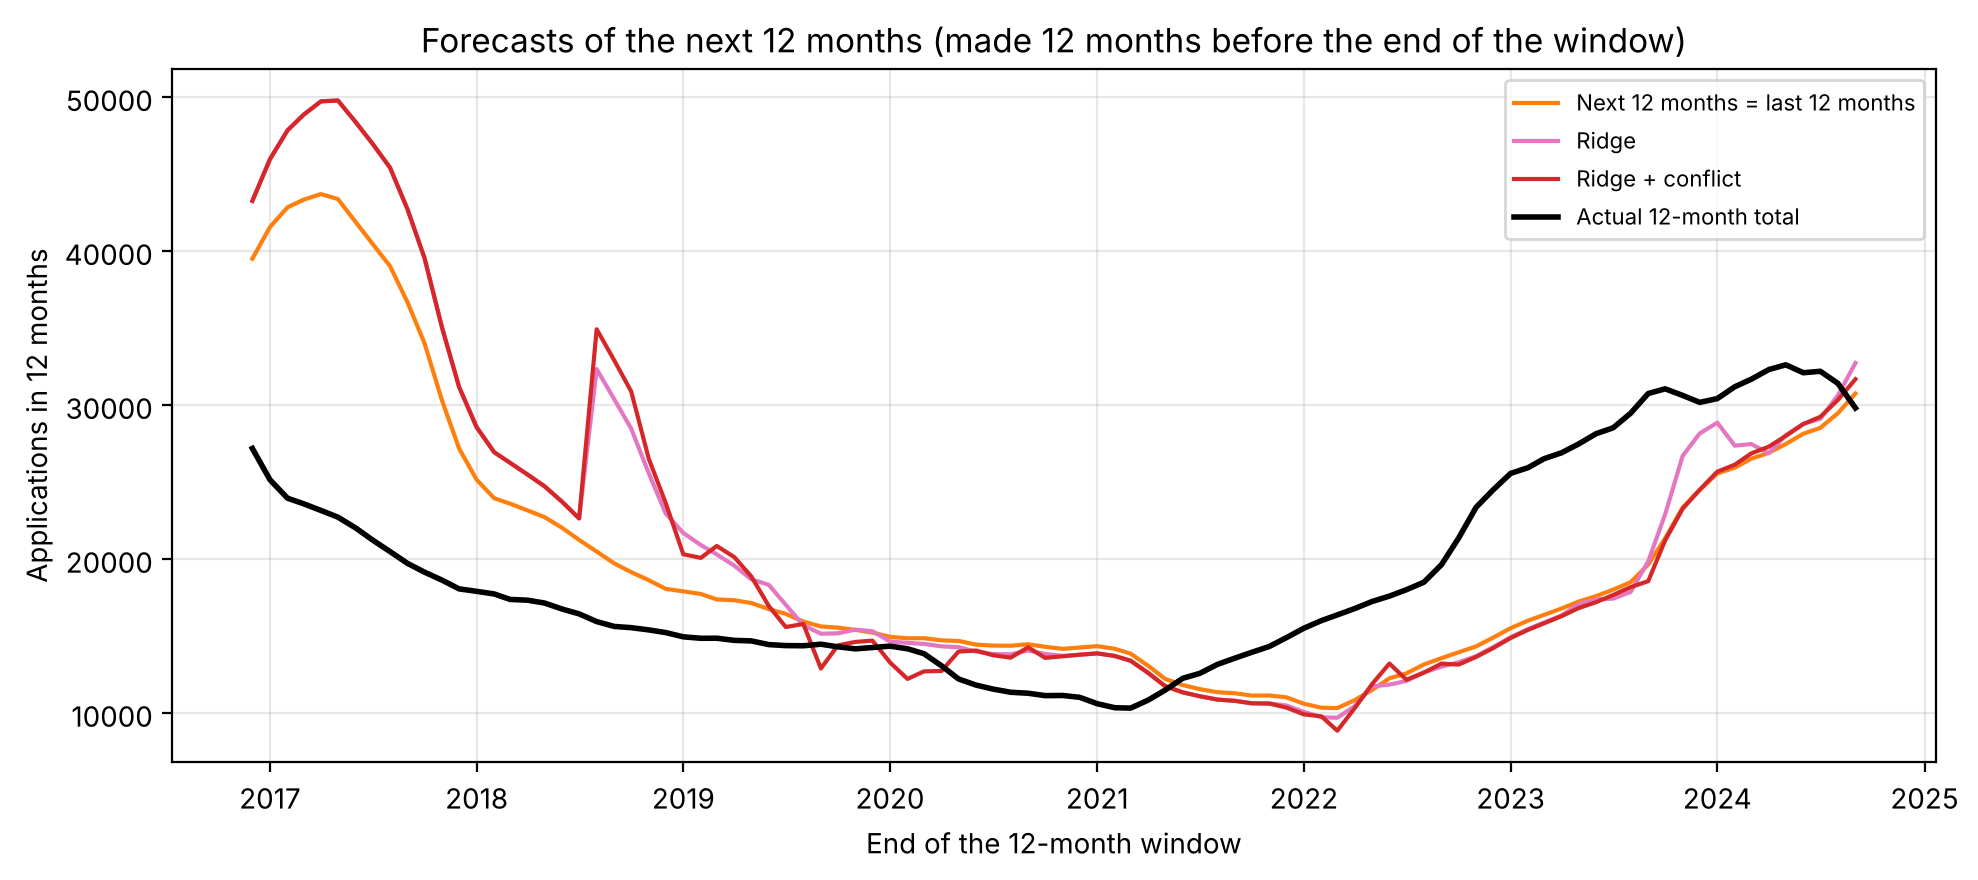

In [29]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, colour in [(reference, plt.cm.tab10(1)), ("Ridge", plt.cm.tab10(6)), ("Ridge + conflict", plt.cm.tab10(3))]:
    one = fc[fc["model"] == name]
    ax.plot(one["origin"] + pd.DateOffset(months=12), one["forecast"], color=colour, label=name)
actual_1y = fc.drop_duplicates("origin")
ax.plot(actual_1y["origin"] + pd.DateOffset(months=12), actual_1y["actual"], color="black", linewidth=2, label="Actual 12-month total")
ax.set_xlabel("End of the 12-month window")
ax.set_ylabel("Applications in 12 months")
ax.set_title("Forecasts of the next 12 months (made 12 months before the end of the window)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_one_year_forecasts.png")
plt.show()

**What we see.**
- In these 94 origins, the next 12 months had on average 19,192 applications. **The simplest rule is the best:** "next 12 months = last 12 months" misses by 6,261 applications on average (31%). The long-run average misses by 7,078, Ridge on the series' own past by 7,707 and the linear regression by 8,029.
- **No extra block helps.** Ridge with the Mediterranean routes (7,672) is practically equal to Ridge alone; with the conflict index (7,910) or the neighbours (7,835) it is worse. The linear regression with the routes (11,181) or the neighbours (13,794) is much worse: without a penalty, it follows the growth of these series far too strongly.
- Year by year (9 origin years, 2015 with December only), no model beats the simple rule in more than 4 years. The blocks beat their own model in 2 to 6 of the 9 years.
- In the figure, all forecasts are far too high for the windows ending in 2017 (about 40,000 to 50,000 instead of 25,000): the models made in 2016 still expected the level of the 2015-16 crisis. From 2022 they are too low: they did not see the rise coming. Ridge and Ridge + conflict jump up again for the windows ending in mid-2018.

**What this means for us.** A year ahead, the past growth is a bad guide: the regressions extend it right before the turning points. The conflict data do not tell us how many people will come a year later either. For annual planning, "the same as last year" plus scenarios is the honest answer, and an error of about 30% has to be expected.

## 19. Would Part B change our choice?

No. Our plan keeps indicators only if they lower the MAE by at least 10% **and** win in most years (section 7). No model with indicators meets this rule (sections 12 to 16): model 2, Ridge with all indicators, is 4.7% better than model 1, a gap of 17 persons against a spread across years of about 220, and it is the best of more than 30 variants tried after the test, so it looks better than it would on new data (notebook 108b). The random walk is a simple rule, not a candidate model: it does not change which model we use, it only makes the gain over the simple rules smaller in the backtest (section 11). A year ahead, no model beats "the same as last year" (section 18).

**The choice of section 8 stands: the linear regression on the series' own past.** `04_test.ipynb` (section 8) shows both families on the test months, for information.

## Summary

**Part A (before the test)**

- **Main comparison ($h = 2$):** best simple baseline = 12-month average (MAE 528 persons); best model = Ridge (MAE 358 persons): **32% lower MAE**, 18% lower RMSE (log).
- **Regressions against SARIMA:** practically equal. Ridge is 3% lower by MAE but slightly worse by RMSE (log); it wins in 9 of 12 years, mostly by small margins; the gap (11 persons) is tiny compared with the spread across years.
- **Robustness:** the own-history models beat the simple rules in all periods, but the advantage is smaller without 2015-16 and 2020, and the best own-history model changes with the period.
- **Route indicator (one block at a time):** adding the detections on the three routes to the regressions makes the MAE at $h = 2$ 1.7% to 4.2% higher; the models with the routes win in only 2 or 3 of 12 years. The only clear gain is in 2015. We do not keep the indicator: it is published too late to help at our cutoff.
- **Final choice (before the test):** the linear regression on the series' own past. It is as good as Ridge (358.0 against 357.9 persons at $h = 2$) and simpler. It is evaluated once on the test period in `04_test.ipynb`, together with the 12-month average.

**Part B (after the test)**

- **Random walk:** MAE 379 at $h = 2$, much better than the 12-month average (528). Our linear regression is 5.4% better and wins in 7 of 12 years, so against this rule the success rule would **not** be met in the backtest; against the planned simple rules it is met (−32%, 9 of 12 years).
- **Two model families:** model 2, Ridge with all indicators (routes, neighbours, Mediterranean routes, conflict index), misses by 341 at $h = 2$ against 358 for model 1 (−4.7% MAE, −5.0% MSE, 7 of 12 years): the success rule is not met. Without a penalty, all indicators make the linear regression worse (379): it overfits.
- **Which data help:** the Mediterranean routes at the UNHCR timing (removing them raises the MSE by 5% to 10%); the Frontex routes and the conflict index add little once they are in; the neighbours make the forecasts worse. Lasso keeps the Mediterranean routes at 88% of the origins.
- **One year ahead:** "next 12 months = last 12 months" is best (MAE 6,261, about 31%); no model or indicator beats it.
- **The choice stays the linear regression.**